# Leading eigenvectors of G(x)

* **Author**: laquitainesteeve@gmail.com
* **Purpose**: 
    * Plot an object image with the receptive fields of two neural models (of monkey areas V1 and V4), and the leading eigenvectors of G(x) for these neural model (as in Fig. 3D–F of the paper).
    * Compare to Fisher Information J(x)'s leading eigenvectors.
* **Tested on**: Ubuntu 24.04.1 LTS (32 cores, 188 GB RAM, Intel(R) Core(TM) i9-14900K ＠3.2 GHz/5.8 GHz); RTX590 GPU (40GB VRAM)

## 1. Setup Jupyter kernel


```bash
# Setup python environment kernel in repository root (linux terminal)
# - create virtual environment path
# - create jupyter kernel
mkdir -p tutorials/env_tuto/ 
conda env create -f tutorials/environment-tuto.yml --prefix env_tuto # (1 min)
conda activate env_tuto
python -m ipykernel install --user --name env_tuto --display-name "env_tuto" 
```


## 2. Download datasets

The pipeline reads three external datasets. Download each from its source, format them and place it under `data/` with this layout:

```
data/
├── tvsd/
│   ├── monkeyN_THINGS_normMUA.mat
│   └── things_imgs.mat
├── things_images/
│   └── object_images/<concept>/<image>.jpg
└── tiny-imagenet-200/
    ├── train/<wnid>/images/<image>.JPEG
    └── val/images/<image>.JPEG
```

* Download TSVD data from g-node:

```bash
bash tutorials/download_tsvd_data.sh # (15 secs, 196MB)
```

* Download things images from osf:

```bash
bash tutorials/download_things_images.sh # (2 min, 4.9GB)
```

* Download tiny-imagenet images from Stanford.edu:

```bash
bash tutorials/download_tiny_imagenet.sh # (50 secs, 481MB)
```

note: Set NEURIPS_DATA_DIR=/path/to/storage to read the datasets from elsewhere



## 3. Download trained encoders & diffusion models

### 3.1. Encoders' backbone

1. **InceptionV3**: The neural encoders' pretrained weights are downloaded by torchvision on first use (cached under $TORCH_HOME).

2. **ResNet-50 ImageNet**: IDEM

3. **Berardino et al. (2017)**: Their ON-OFF front-end ships with plenoptic (OnOff(pretrained=True)); nothing to download by hand.

### 3.2 Encoders' readout and diffusion weights



* The checkpoints are neural encoders fitted to the neural data we downloaded. The only part that was fitted is a small readout on top of the torchvision weights.

```
runs/
├── diffusion/
│   └── inception
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
│   └── resnet50
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
├── encoders/
│   ├── inception
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
│   └── resnet50
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
```

* Download the weights in `runs/`

```bash
huggingface-cli download steevelaquitaine/multigeom --local-dir runs
```

## 4. Import packages

We use the models checkpoints in `runs/`.

In [24]:
# import built-in packages 
import os, sys, subprocess
from pathlib import Path
import torch
import copy, time
import matplotlib.pyplot as plt
from PIL import Image

# import custom package
from src.utils import load_config, get_device, make_generator
from src.data_loaders import TinyImageNetDataset, CANONICAL_TRANSFORM
from src.encoders import build_encoder
from src.diffusion_model import build_diffusion_model, build_scheduler
from src.estimator import conditional_pair_estimate
from src.fisher import fisher_eigendecomposition
from figures.fig3 import panel_rf, panel_eigvecs
from figures._style import panel_label

# move to the repository root (the folder containing pyproject.toml)
root = Path.cwd().resolve()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
print("repo root:", root)

# choose an encoder
ENC, AREA = "inception", "V1"

# load the encoder, diffusion and estimator configs
enc_cfg = load_config(f"configs/{ENC}.yaml")
diff_cfg = load_config("configs/diffusion.yaml")
est_cfg = load_config("configs/estimator.yaml")

# choose the image for which to estimate G(x) and J(x): the example image of paper Fig. 3D
# (first TinyImageNet *training* image of the class n01644900, a frog)
IMG_PATH = "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG"
N_MC = 50   # (default: 200) number of monte carlo samples                    

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/MultiscaleInformationGeometry
device: cuda


## 5. Load one model pair

Encoder f_φ (frozen backbone + fitted readout) and the conditional diffusion model ε_θ, here for **inception / V1**. Change `ENC` and `AREA` to look at another configuration.

In [23]:
%%time 

# encoder
encoder = build_encoder(enc_cfg).to(device)
encoder.load_state_dict(torch.load(f"runs/encoders/{ENC}/{AREA}/best_model.pt", map_location=device, weights_only=False)["model_state_dict"])
encoder.eval()

# diffusion model
unet = build_diffusion_model(diff_cfg).to(device)
diff_ckpt = torch.load(f"runs/diffusion/{ENC}/{AREA}/final_model.pt", map_location=device, weights_only=False)
unet.load_state_dict(diff_ckpt["model_state_dict"])
unet.eval()
scheduler = build_scheduler(diff_cfg)
alphas_cumprod = scheduler.alphas_cumprod.to(device)

# report info
print("diffusion epoch:", diff_ckpt.get("epoch"))

diffusion epoch: 120
CPU times: user 736 ms, sys: 66.5 ms, total: 802 ms
Wall time: 429 ms


## 6. Estimate G(x) and J(x), and plot paper Fig. 3D-F

Estimate the top eigenpairs of the multi-scale Fisher metric G(x) (conditional-pair estimator, Algorithm 1) and of the closed-form Fisher metric J(x) for the example image of Fig. 3D, once with the V1 encoder and once with the V4 encoder (inception). Then plot Fig. 3D-F with the plotting functions of `figures/fig3.py`: the image with the V1 and V4 receptive fields (D), and the leading four eigenvectors of G (E) and of J (F), V1 on top and V4 below.

`N_MC` is the number of Monte-Carlo samples. The paper uses 200 (about 15 s per image and area on this GPU); use a smaller value for a quick look. Results from this cell are not saved.

#### 6.1 Compute

* **execution time**: about 6 secs with `N_MC = 50` (about 30 secs with 200)

In [ ]:
%%time 

cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = N_MC
sigma = float(cfg.monte_carlo.observation_noise_sigma)

x = CANONICAL_TRANSFORM(Image.open(IMG_PATH)).unsqueeze(0).to(device)   # [1, 1, 64, 64] in [-1, 1]

ckpts, records = {}, {}      # per area: encoder checkpoint, and the image + eigenpairs of G and J
for area in ["V1", "V4"]:
    # encoder and diffusion model fitted to this area
    ckpts[area] = torch.load(f"runs/encoders/{ENC}/{area}/best_model.pt", map_location="cpu", weights_only=False)
    area_encoder = build_encoder(enc_cfg).to(device)
    area_encoder.load_state_dict(ckpts[area]["model_state_dict"])
    area_encoder.eval()
    area_unet = build_diffusion_model(diff_cfg).to(device)
    area_unet.load_state_dict(torch.load(f"runs/diffusion/{ENC}/{area}/final_model.pt", map_location=device, weights_only=False)["model_state_dict"])
    area_unet.eval()

    # G(x) (conditional-pair estimator) and J(x) (closed form)
    g = conditional_pair_estimate(image=x, encoder=area_encoder, unet=area_unet, alphas_cumprod=alphas_cumprod,
                                  cfg=cfg, device=device, generator=make_generator(int(cfg.seed), device))
    j = fisher_eigendecomposition(image=x, encoder=area_encoder, sigma=sigma, top_k=int(cfg.fisher_baseline.top_k), device=device)
    records[area] = {"image": x.cpu(),
                     "G_eigenvalues": g.eigenvalues.cpu(), "G_eigenvectors": g.eigenvectors.cpu(),
                     "J_eigenvalues": j.eigenvalues.cpu(), "J_eigenvectors": j.eigenvectors.cpu()}
    print(area, "G:", tuple(g.eigenvectors.shape), " J:", tuple(j.eigenvectors.shape))

V1 G: (50, 4096)  J: (50, 4096)
V4 G: (50, 4096)  J: (50, 4096)
CPU times: user 28.1 s, sys: 1.13 s, total: 29.2 s
Wall time: 6.8 s


#### 6.2. Plot

* The diffusion checkpoints report epoch 120, not the 200 used for the paper. 
* Monte carlo noise of the G(x) estimator: seed 42.
* The encoder weight checkpoint may differ from what the paper's.
* execution time: < 1 sec

CPU times: user 427 ms, sys: 2.01 ms, total: 429 ms
Wall time: 60.3 ms


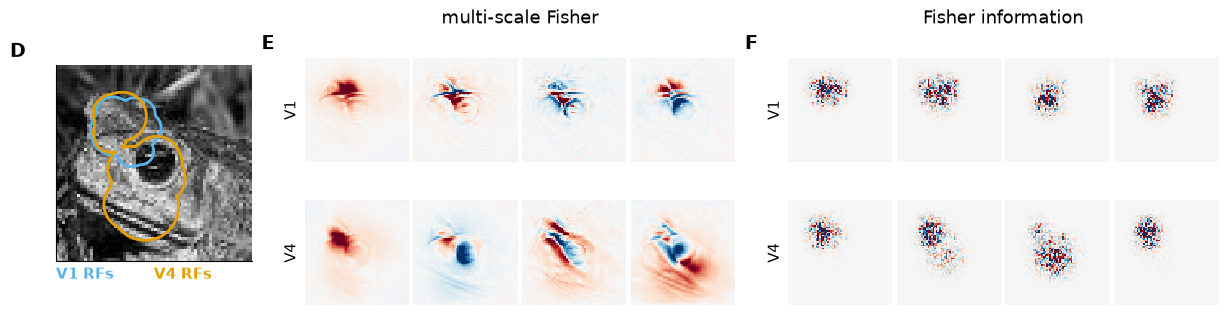

In [ ]:
%%time 

fig = plt.figure(figsize=(15, 3.9))
spec = fig.add_gridspec(1, 3, width_ratios=[1.0, 2.2, 2.2], wspace=0.15)
ax_d = fig.add_subplot(spec[0])
panel_rf(ax_d, records["V1"]["image"], ckpts)                   # D: image with V1 and V4 receptive fields
ax_e = panel_eigvecs(fig, spec[1], records, "G", 4)             # E: leading eigenvectors of G(x)
ax_f = panel_eigvecs(fig, spec[2], records, "J", 4)             # F: leading eigenvectors of J(x)
for letter, ax in zip("DEF", (ax_d, ax_e, ax_f)):
    panel_label(fig, ax, letter)
fig